# 02 · Model training & evaluation

Trains and evaluates the CAD, LAD, LCX and RCA classifiers.

| Step | What |
| --- | --- |
| Split | Stratified 80/20 dev/test (stratified on number of stenotic vessels). Test set touched once. |
| Model zoo | Elastic-net LogReg, SVM-RBF, Random Forest, Extra Trees, XGBoost, LightGBM, CatBoost |
| Validation | 5-fold × 3-repeat **nested** CV on dev; Optuna TPE (20 trials, inner 3-fold ROC-AUC) re-run inside every outer fold |
| Ensemble | Soft vote of the top-3 models per target, Platt-calibrated on out-of-fold votes |
| Multi-label | Independent models vs classifier chain CAD → LAD → LCX → RCA (paired on the same folds) |
| Threshold | F1-optimal threshold from out-of-fold dev predictions of the full final model |
| Test metrics | accuracy, precision, recall, specificity, **F1**, ROC-AUC, PR-AUC, Brier, MCC with 95 % stratified bootstrap CIs; DeLong / McNemar vs logistic baseline |

Set `RETRAIN = True` to rerun the whole pipeline from here (≈1–2 h on 8 cores); otherwise the
artifacts written by `uv run python -m vascora_ml.train` are loaded.

In [1]:
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from vascora_ml import config, data, models

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)
REPORTS = config.REPORTS_DIR
REPORTS.mkdir(exist_ok=True)
TARGETS = data.target_keys()
TARGET_LABELS = {t: data.load_registry()["targets"][t]["label"] for t in TARGETS}
FEATURE_LABELS = {f.key: f.label for f in data.features()}

In [2]:
from vascora_ml.evaluation import METRICS, classification_metrics
from vascora_ml.train import TrainConfig, ensemble_folds, prepare, run, summarize

RETRAIN = False
A = config.ARTIFACTS_DIR
if RETRAIN or not (A / "metrics.json").exists():
    run(TrainConfig())

metrics = json.loads((A / "metrics.json").read_text())
folds = pd.read_csv(A / "cv_folds.csv")
oof_cv = pd.read_csv(A / "cv_oof.csv.gz")
chain_df = pd.read_csv(A / "chain_experiment.csv")
bundle = joblib.load(A / "vascora_model.joblib")
model = bundle["model"]
ds = prepare()
MODEL_LABELS = {k: v.label for k, v in models.ZOO.items()} | {"ensemble": "Top-3 soft-vote ensemble"}
print(metrics["validation"]["scheme"])
print("generated:", metrics["generated_at"])

3x repeated stratified 5-fold nested CV (Optuna TPE, 20 trials, inner 3-fold ROC-AUC) on the 242-patient dev set; untouched 61-patient stratified hold-out test set
generated: 2026-10-13T16:29:48+00:00


In [3]:
split = pd.DataFrame({
    "dev prevalence": ds.Y_dev.mean(), "test prevalence": ds.Y_test.mean(),
    "dev positives": ds.Y_dev.sum(), "test positives": ds.Y_test.sum(),
}).rename(index=TARGET_LABELS)
print(f"dev = {len(ds.Y_dev)} patients, test = {len(ds.Y_test)} patients")
split

dev = 242 patients, test = 61 patients


,dev prevalence,test prevalence,dev positives,test positives
Coronary Artery Disease,0.711,0.721,172,44
Left Anterior Descending,0.591,0.557,143,34
Left Circumflex,0.380,0.443,92,27
Right Coronary Artery,0.380,0.361,92,22


## 1. Nested cross-validation: model comparison

Mean ± SD over 15 outer folds. Probabilities are scored at 0.5 for the threshold metrics here
(threshold tuning only happens for the final model).

In [4]:
chosen = {t: [m["name"] for m in metrics["targets"][t]["model"]["members"]] for t in TARGETS}
ens = ensemble_folds(oof_cv, chosen)
allf = pd.concat([folds, ens], ignore_index=True)
summary = summarize(allf, ["target", "model"])

def fmt(metric):
    s = summary.assign(v=lambda d: d[f"{metric}_mean"].map("{:.3f}".format) + " ± "
                       + d[f"{metric}_std"].map("{:.3f}".format))
    tab = s.pivot(index="model", columns="target", values="v")[TARGETS]
    order = summary[summary.target == "CAD"].sort_values(f"{metric}_mean", ascending=False).model
    return tab.loc[order].rename(index=MODEL_LABELS)

for m in ["roc_auc", "f1", "accuracy"]:
    display(Markdown(f"**CV {m}**"))
    display(fmt(m))

**CV roc_auc**

target,CAD,LAD,LCX,RCA
model,,,,
Top-3 soft-vote ensemble,0.952 ± 0.026,0.861 ± 0.034,0.711 ± 0.053,0.751 ± 0.042
CatBoost,0.950 ± 0.027,0.856 ± 0.029,0.700 ± 0.068,0.712 ± 0.046
Elastic-net Logistic Regression,0.944 ± 0.032,0.845 ± 0.037,0.690 ± 0.057,0.746 ± 0.045
Extra Trees,0.942 ± 0.032,0.849 ± 0.040,0.672 ± 0.066,0.747 ± 0.045
XGBoost,0.942 ± 0.031,0.858 ± 0.036,0.711 ± 0.053,0.716 ± 0.064
LightGBM,0.940 ± 0.026,0.855 ± 0.039,0.701 ± 0.047,0.700 ± 0.070
Random Forest,0.939 ± 0.035,0.856 ± 0.041,0.702 ± 0.049,0.707 ± 0.056
"SVM (RBF, Platt)",0.938 ± 0.030,0.846 ± 0.042,0.666 ± 0.062,0.723 ± 0.043


**CV f1**

target,CAD,LAD,LCX,RCA
model,,,,
Top-3 soft-vote ensemble,0.935 ± 0.028,0.831 ± 0.034,0.495 ± 0.083,0.446 ± 0.075
LightGBM,0.933 ± 0.029,0.818 ± 0.047,0.488 ± 0.106,0.435 ± 0.118
CatBoost,0.932 ± 0.034,0.821 ± 0.031,0.401 ± 0.194,0.421 ± 0.126
Extra Trees,0.929 ± 0.032,0.837 ± 0.048,0.346 ± 0.091,0.421 ± 0.092
XGBoost,0.929 ± 0.029,0.821 ± 0.038,0.476 ± 0.108,0.478 ± 0.104
"SVM (RBF, Platt)",0.927 ± 0.027,0.841 ± 0.049,0.354 ± 0.088,0.427 ± 0.114
Random Forest,0.916 ± 0.029,0.826 ± 0.043,0.394 ± 0.079,0.392 ± 0.112
Elastic-net Logistic Regression,0.915 ± 0.043,0.811 ± 0.058,0.343 ± 0.199,0.368 ± 0.180


**CV accuracy**

target,CAD,LAD,LCX,RCA
model,,,,
Top-3 soft-vote ensemble,0.904 ± 0.043,0.785 ± 0.039,0.671 ± 0.049,0.665 ± 0.043
LightGBM,0.901 ± 0.044,0.773 ± 0.050,0.668 ± 0.043,0.661 ± 0.056
CatBoost,0.898 ± 0.052,0.774 ± 0.035,0.649 ± 0.064,0.682 ± 0.046
XGBoost,0.897 ± 0.043,0.774 ± 0.043,0.668 ± 0.037,0.668 ± 0.052
Extra Trees,0.895 ± 0.050,0.794 ± 0.057,0.620 ± 0.065,0.665 ± 0.051
"SVM (RBF, Platt)",0.893 ± 0.041,0.803 ± 0.057,0.640 ± 0.028,0.647 ± 0.050
Random Forest,0.873 ± 0.044,0.780 ± 0.049,0.640 ± 0.049,0.667 ± 0.051
Elastic-net Logistic Regression,0.872 ± 0.069,0.755 ± 0.086,0.632 ± 0.041,0.654 ± 0.053


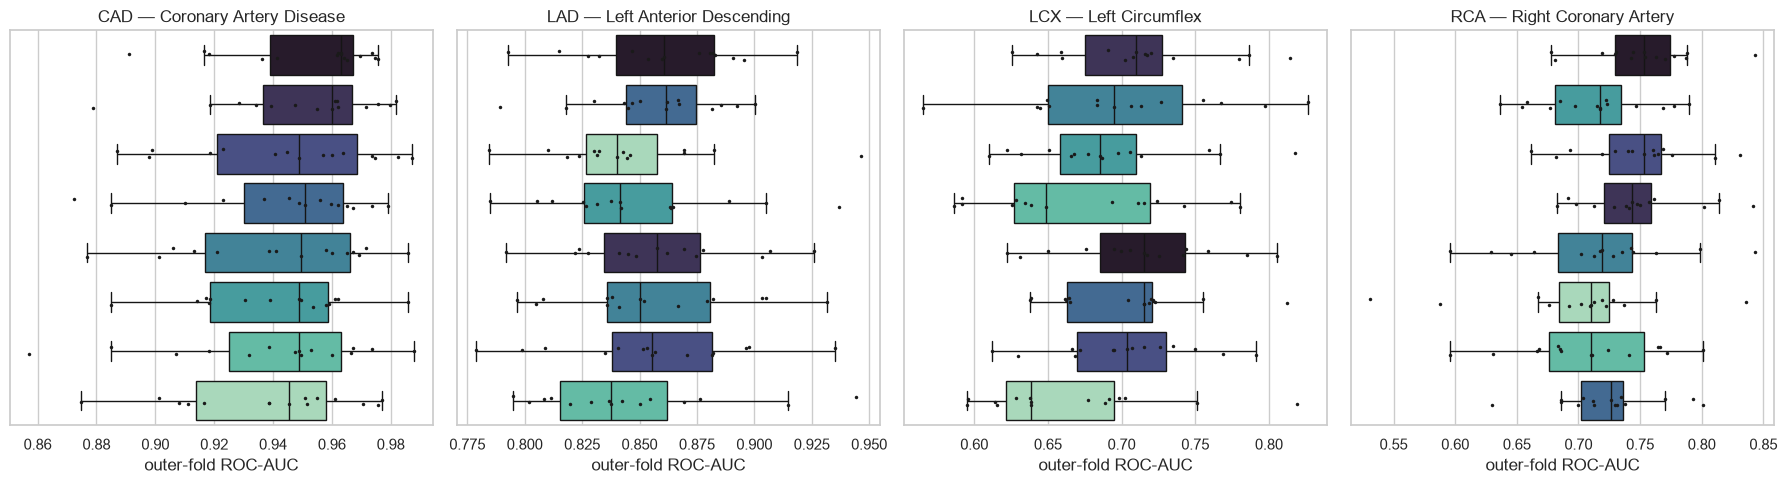

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5), sharey=True)
for ax, t in zip(axes, TARGETS):
    d = allf[allf.target == t]
    order = d.groupby("model").roc_auc.mean().sort_values(ascending=False).index
    sns.boxplot(data=d, y="model", x="roc_auc", order=order, ax=ax, palette="mako",
                showfliers=False)
    sns.stripplot(data=d, y="model", x="roc_auc", order=order, ax=ax, color="k", size=2.5)
    ax.set_title(f"{t} — {TARGET_LABELS[t]}"); ax.set_xlabel("outer-fold ROC-AUC"); ax.set_ylabel("")
    ax.set_yticklabels([MODEL_LABELS[o.get_text()] for o in ax.get_yticklabels()])
plt.tight_layout(); plt.savefig(REPORTS / "cv_auc_by_model.png", dpi=150); plt.show()

In [6]:
full = summary.copy()
cols = ["accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "pr_auc", "brier"]
ens_tab = full[full.model == "ensemble"].set_index("target").loc[TARGETS, [f"{c}_mean" for c in cols]]
ens_tab.columns = cols
display(Markdown("**Ensemble — all CV metrics (mean over outer folds, threshold 0.5)**"))
ens_tab.rename(index=TARGET_LABELS)

**Ensemble — all CV metrics (mean over outer folds, threshold 0.5)**

,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,brier
target,,,,,,,,
Coronary Artery Disease,0.904,0.902,0.971,0.738,0.935,0.952,0.980,0.084
Left Anterior Descending,0.785,0.776,0.903,0.628,0.831,0.861,0.893,0.156
Left Circumflex,0.671,0.595,0.433,0.817,0.495,0.711,0.576,0.211
Right Coronary Artery,0.665,0.623,0.361,0.855,0.446,0.751,0.628,0.200


### Ensemble vs logistic-regression baseline (paired by outer fold)

In [7]:
rows = []
for t in TARGETS:
    a = allf[(allf.target == t) & (allf.model == "ensemble")].set_index(["repeat", "fold"]).roc_auc
    b = allf[(allf.target == t) & (allf.model == "logreg")].set_index(["repeat", "fold"]).roc_auc
    d = (a - b).dropna()
    rows.append({"target": t, "mean AUC gain": d.mean(), "sd": d.std(),
                 "folds won": f"{(d > 0).sum()}/{len(d)}"})
pd.DataFrame(rows).set_index("target")

,mean AUC gain,sd,folds won
target,,,
CAD,0.008,0.016,11/15
LAD,0.016,0.031,11/15
LCX,0.021,0.057,10/15
RCA,0.004,0.020,8/15


## 2. Independent models vs classifier chain

Each vessel model optionally receives the out-of-fold predicted probabilities of the earlier
targets in the chain (never the true labels). Same outer folds, default hyper-parameters,
paired AUC difference.

In [8]:
piv = chain_df.pivot_table(index=["target", "model", "repeat", "fold"], columns="mode",
                           values="roc_auc").reset_index()
piv["gain"] = piv["chain"] - piv["independent"]
tab = piv.groupby(["target", "model"]).agg(independent=("independent", "mean"), chain=("chain", "mean"),
                                           gain=("gain", "mean"), gain_sd=("gain", "std")).loc[TARGETS]
display(tab)
decision = pd.DataFrame({t: metrics["targets"][t]["chain"] for t in TARGETS}).T
display(decision)

independent  chain   gain  gain_sd
target model                                       
CAD    catboost        0.955  0.955  0.000    0.000
       logreg          0.949  0.949  0.000    0.000
LAD    catboost        0.844  0.848  0.004    0.025
       logreg          0.845  0.850  0.005    0.008
LCX    catboost        0.695  0.719  0.024    0.033
       logreg          0.704  0.715  0.011    0.016
RCA    catboost        0.674  0.697  0.023    0.041
       logreg          0.757  0.770  0.014    0.013

,auc_gain,auc_gain_std,use_chain
CAD,0.0,0.0,False
LAD,0.004,0.018,False
LCX,0.017,0.026,True
RCA,0.018,0.03,True


## 3. Final model

Chosen members are re-tuned on the full dev set (Optuna, 40 trials, 5-fold), combined into a
soft vote and Platt-calibrated. Decision thresholds maximise F1 on out-of-fold dev predictions.

In [9]:
rows = []
for t in TARGETS:
    m = metrics["targets"][t]["model"]
    rows.append({"target": t, "members": ", ".join(MODEL_LABELS[x["name"]] for x in m["members"]),
                 "chain parents": ", ".join(m["chain_parents"]) or "—",
                 "threshold (F1-opt)": m["threshold"],
                 "dev OOF F1": metrics["targets"][t]["dev_oof"]["f1"],
                 "dev OOF AUC": metrics["targets"][t]["dev_oof"]["roc_auc"]})
pd.DataFrame(rows).set_index("target")

,members,chain parents,threshold (F1-opt),dev OOF F1,dev OOF AUC
target,,,,,
CAD,"CatBoost, Elastic-net Logistic Regression, Ext...",—,0.505,0.948,0.947
LAD,"XGBoost, Random Forest, CatBoost",—,0.360,0.859,0.865
LCX,"XGBoost, Random Forest, LightGBM","CAD, LAD",0.270,0.651,0.730
RCA,"Extra Trees, Elastic-net Logistic Regression, ...","CAD, LAD, LCX",0.305,0.675,0.769


## 4. Held-out test set (61 patients, never used for training, selection or thresholds)

In [10]:
show = ["accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "pr_auc", "mcc", "brier"]
rows = {}
for t in TARGETS:
    r = metrics["targets"][t]["test"]
    rows[t] = {m: f"{r['metrics'][m]:.3f} [{r['ci95'][m][0]:.2f}, {r['ci95'][m][1]:.2f}]" for m in show}
test_tab = pd.DataFrame(rows).T[show]
test_tab.index = [f"{t} — {TARGET_LABELS[t]}" for t in TARGETS]
display(Markdown("**Test metrics at the F1-optimal threshold — point estimate [95 % bootstrap CI]**"))
test_tab

**Test metrics at the F1-optimal threshold — point estimate [95 % bootstrap CI]**

,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,mcc,brier
CAD — Coronary Artery Disease,"0.754 [0.64, 0.85]","0.854 [0.77, 0.94]","0.795 [0.68, 0.91]","0.647 [0.41, 0.88]","0.824 [0.74, 0.90]","0.846 [0.74, 0.93]","0.946 [0.91, 0.98]","0.423 [0.17, 0.66]","0.167 [0.10, 0.24]"
LAD — Left Anterior Descending,"0.754 [0.64, 0.85]","0.744 [0.65, 0.85]","0.853 [0.74, 0.97]","0.630 [0.44, 0.81]","0.795 [0.71, 0.88]","0.810 [0.70, 0.91]","0.855 [0.77, 0.93]","0.499 [0.26, 0.71]","0.191 [0.12, 0.26]"
LCX — Left Circumflex,"0.705 [0.59, 0.80]","0.636 [0.53, 0.76]","0.778 [0.59, 0.93]","0.647 [0.47, 0.79]","0.700 [0.58, 0.81]","0.755 [0.63, 0.87]","0.701 [0.56, 0.84]","0.423 [0.20, 0.64]","0.205 [0.15, 0.26]"
RCA — Right Coronary Artery,"0.607 [0.48, 0.72]","0.467 [0.34, 0.59]","0.636 [0.45, 0.82]","0.590 [0.44, 0.74]","0.538 [0.39, 0.67]","0.689 [0.55, 0.81]","0.600 [0.44, 0.76]","0.217 [-0.04, 0.45]","0.220 [0.17, 0.28]"


In [11]:
rows = []
for t in TARGETS:
    r = metrics["targets"][t]["test"]
    for name, key, thr in [("F1-optimal (deployed)", "metrics", metrics["targets"][t]["model"]["threshold"]),
                           ("Youden J", "metrics_at_youden", r["youden_threshold"]),
                           ("0.5", "metrics_at_0_5", 0.5)]:
        rows.append({"target": t, "threshold rule": name, "threshold": thr,
                     **{m: r[key][m] for m in ["accuracy", "precision", "recall", "f1"]}})
display(Markdown("**Effect of the decision threshold on test metrics**"))
pd.DataFrame(rows).set_index(["target", "threshold rule"])

**Effect of the decision threshold on test metrics**

threshold  accuracy  precision  recall     f1
target threshold rule                                                      
CAD    F1-optimal (deployed)      0.505     0.754      0.854   0.795  0.824
       Youden J                   0.505     0.754      0.854   0.795  0.824
       0.5                        0.500     0.738      0.833   0.795  0.814
LAD    F1-optimal (deployed)      0.360     0.754      0.744   0.853  0.795
       Youden J                   0.560     0.705      0.767   0.676  0.719
       0.5                        0.500     0.738      0.781   0.735  0.758
LCX    F1-optimal (deployed)      0.270     0.705      0.636   0.778  0.700
       Youden J                   0.345     0.689      0.625   0.741  0.678
       0.5                        0.500     0.689      0.682   0.556  0.612
RCA    F1-optimal (deployed)      0.305     0.607      0.467   0.636  0.538
       Youden J                   0.305     0.607      0.467   0.636  0.538
       0.5                        0.500     0.639      0.500   0.409  0.450

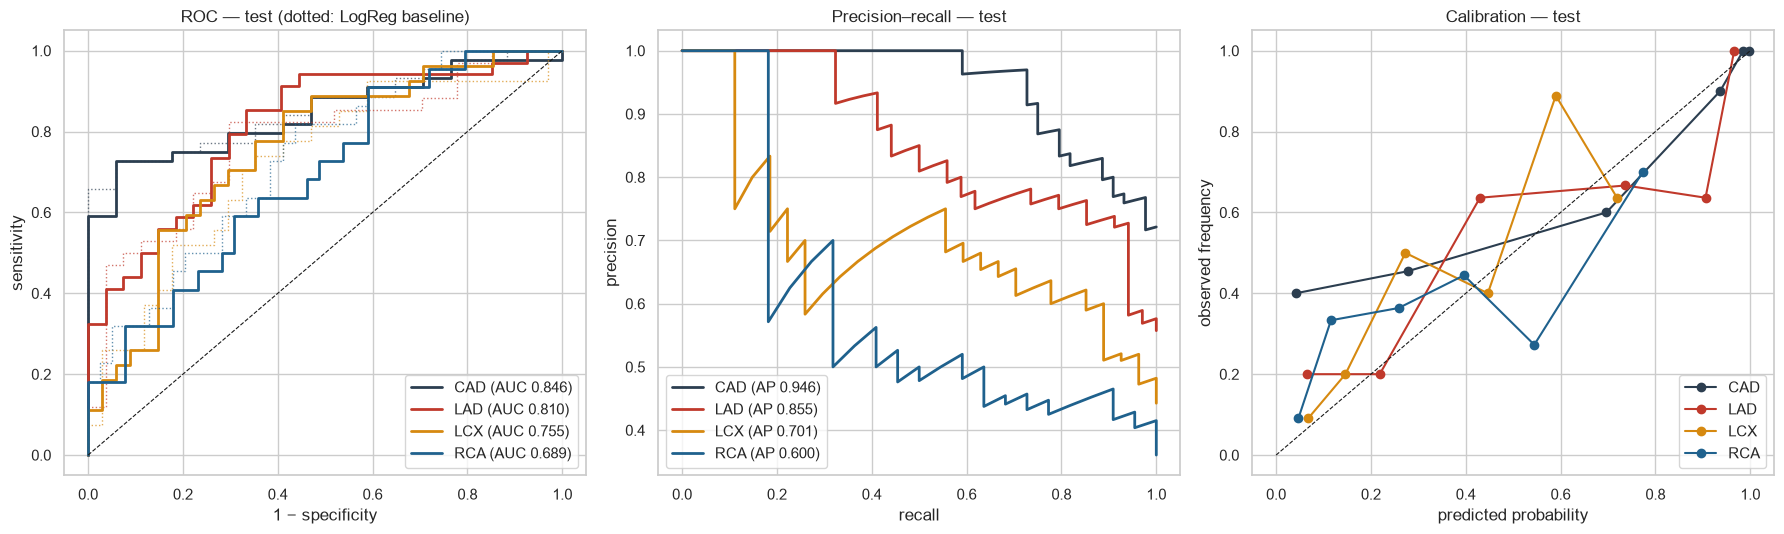

In [12]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import (ConfusionMatrixDisplay, auc, precision_recall_curve, roc_curve,
                             average_precision_score)

probs = model.predict_proba(ds.Xb_test)
base_models = {t: models.build("logreg").fit(ds.Xb_dev, ds.Y_dev[t]) for t in TARGETS}
colors = dict(zip(TARGETS, ["#2c3e50", "#c0392b", "#d68910", "#1f618d"]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for t in TARGETS:
    y, p = ds.Y_test[t], probs[t]
    fpr, tpr, _ = roc_curve(y, p)
    axes[0].plot(fpr, tpr, color=colors[t], lw=2, label=f"{t} (AUC {auc(fpr, tpr):.3f})")
    pb = base_models[t].predict_proba(ds.Xb_test)[:, 1]
    fb, tb, _ = roc_curve(y, pb)
    axes[0].plot(fb, tb, color=colors[t], lw=1, ls=":", alpha=0.7)
    pr, rc, _ = precision_recall_curve(y, p)
    axes[1].plot(rc, pr, color=colors[t], lw=2, label=f"{t} (AP {average_precision_score(y, p):.3f})")
    fp_, mp_ = calibration_curve(y, p, n_bins=6, strategy="quantile")
    axes[2].plot(mp_, fp_, "o-", color=colors[t], label=t)
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set(title="ROC — test (dotted: LogReg baseline)", xlabel="1 − specificity", ylabel="sensitivity")
axes[1].set(title="Precision–recall — test", xlabel="recall", ylabel="precision")
axes[2].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[2].set(title="Calibration — test", xlabel="predicted probability", ylabel="observed frequency")
for ax in axes: ax.legend(loc="lower right" if ax is not axes[1] else "lower left")
plt.tight_layout(); plt.savefig(REPORTS / "test_roc_pr_calibration.png", dpi=150); plt.show()

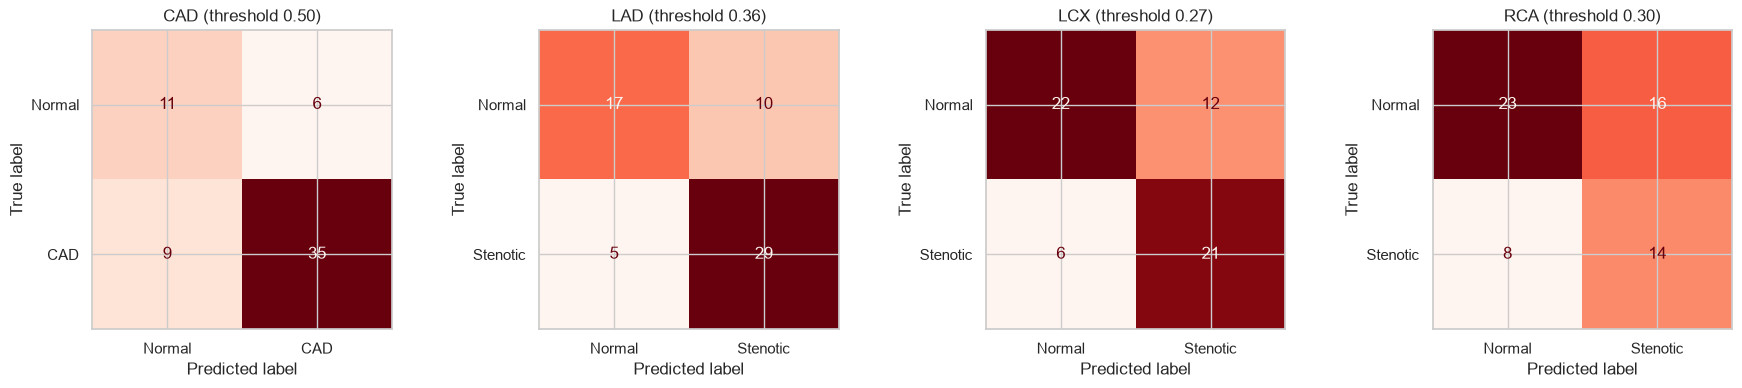

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, t in zip(axes, TARGETS):
    thr = model.thresholds[t]
    ConfusionMatrixDisplay.from_predictions(ds.Y_test[t], (probs[t] >= thr).astype(int),
        display_labels=["Normal", "Stenotic" if t != "CAD" else "CAD"], ax=ax, cmap="Reds",
        colorbar=False)
    ax.set_title(f"{t} (threshold {thr:.2f})")
plt.tight_layout(); plt.savefig(REPORTS / "test_confusion.png", dpi=150); plt.show()

### Statistical comparison with the logistic-regression baseline (test set)

In [14]:
rows = []
for t in TARGETS:
    b = metrics["targets"][t]["test"]["baseline"]
    rows.append({"target": t, "ensemble AUC": b["delong"]["auc_a"], "baseline AUC": b["delong"]["auc_b"],
                 "DeLong p": b["delong"]["p_value"], "baseline F1 @0.5": b["metrics"]["f1"],
                 "ensemble F1": metrics["targets"][t]["test"]["metrics"]["f1"],
                 "McNemar p": b["mcnemar"]["p_value"]})
pd.DataFrame(rows).set_index("target")

,ensemble AUC,baseline AUC,DeLong p,baseline F1 @0.5,ensemble F1,McNemar p
target,,,,,,
CAD,0.846,0.857,0.407,0.837,0.824,1.000
LAD,0.810,0.776,0.266,0.765,0.795,1.000
LCX,0.755,0.720,0.355,0.512,0.700,0.629
RCA,0.689,0.730,0.104,0.513,0.538,0.267


With 61 test patients the CIs are wide and a 0.02–0.05 AUC difference cannot reach
significance; the repeated nested CV (15 folds on 242 patients) is the more precise estimate of
expected performance, the held-out test is the unbiased sanity check.

## 5. Per-patient uncertainty

Each prediction carries a 90 % bootstrap interval from 10 refits of the full model on resampled
dev data (shown in the dashboard as an uncertainty halo).

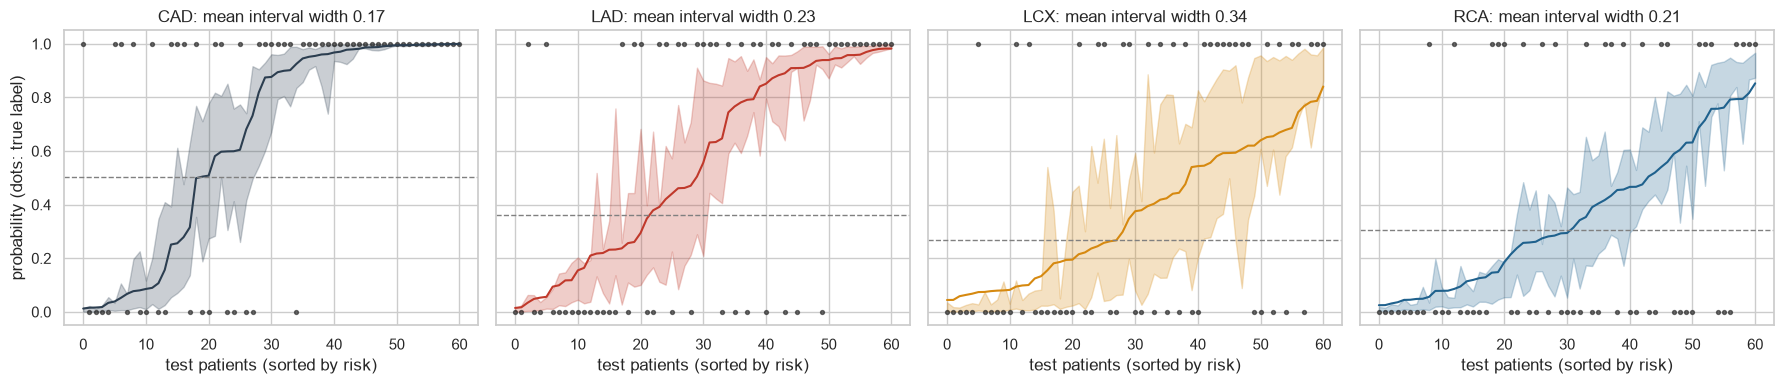

In [15]:
lo_hi = model.predict_interval(ds.Xb_test)
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, t in zip(axes, TARGETS):
    order = np.argsort(probs[t])
    lo, hi = lo_hi[t]
    ax.fill_between(range(len(order)), lo[order], hi[order], color=colors[t], alpha=0.25)
    ax.plot(probs[t][order], color=colors[t])
    ax.scatter(range(len(order)), ds.Y_test[t].to_numpy()[order], s=8, c="k", alpha=0.6)
    ax.axhline(model.thresholds[t], ls="--", c="grey", lw=1)
    ax.set_title(f"{t}: mean interval width {np.mean(hi - lo):.2f}")
    ax.set_xlabel("test patients (sorted by risk)")
axes[0].set_ylabel("probability (dots: true label)")
plt.tight_layout(); plt.savefig(REPORTS / "test_uncertainty.png", dpi=150); plt.show()

In [16]:
lines = ["| Target | ROC-AUC | F1 | Accuracy | Precision | Recall |", "| --- | --- | --- | --- | --- | --- |"]
for t in TARGETS:
    r = metrics["targets"][t]["test"]
    cell = lambda m: f"{r['metrics'][m]:.3f} ({r['ci95'][m][0]:.2f}–{r['ci95'][m][1]:.2f})"
    lines.append(f"| {t} | " + " | ".join(cell(m) for m in ["roc_auc", "f1", "accuracy", "precision", "recall"]) + " |")
cv_lines = ["| Target | CV ROC-AUC | CV F1 |", "| --- | --- | --- |"]
for t in TARGETS:
    c = metrics["targets"][t]["cv"]["ensemble"]
    cv_lines.append(f"| {t} | {c['roc_auc']['mean']:.3f} ± {c['roc_auc']['std']:.3f} | {c['f1']['mean']:.3f} ± {c['f1']['std']:.3f} |")
display(Markdown("### Summary — held-out test (95 % CI)\n" + "\n".join(lines)
                 + "\n\n### Summary — nested CV ensemble (mean ± SD)\n" + "\n".join(cv_lines)))

### Summary — held-out test (95 % CI)
| Target | ROC-AUC | F1 | Accuracy | Precision | Recall |
| --- | --- | --- | --- | --- | --- |
| CAD | 0.846 (0.74–0.93) | 0.824 (0.74–0.90) | 0.754 (0.64–0.85) | 0.854 (0.77–0.94) | 0.795 (0.68–0.91) |
| LAD | 0.810 (0.70–0.91) | 0.795 (0.71–0.88) | 0.754 (0.64–0.85) | 0.744 (0.65–0.85) | 0.853 (0.74–0.97) |
| LCX | 0.755 (0.63–0.87) | 0.700 (0.58–0.81) | 0.705 (0.59–0.80) | 0.636 (0.53–0.76) | 0.778 (0.59–0.93) |
| RCA | 0.689 (0.55–0.81) | 0.538 (0.39–0.67) | 0.607 (0.48–0.72) | 0.467 (0.34–0.59) | 0.636 (0.45–0.82) |

### Summary — nested CV ensemble (mean ± SD)
| Target | CV ROC-AUC | CV F1 |
| --- | --- | --- |
| CAD | 0.952 ± 0.026 | 0.935 ± 0.028 |
| LAD | 0.861 ± 0.034 | 0.831 ± 0.034 |
| LCX | 0.711 ± 0.053 | 0.495 ± 0.083 |
| RCA | 0.751 ± 0.042 | 0.446 ± 0.075 |